# Tutorial 5a - NMR parameters from .magres files


```
      _
    /|_|\   
   / / \ \  
  /_/   \_\  
  \ \   / /  
   \ \_/ /  
    \|_|/  

```
SOPRANO: a Python library for generation, manipulation and analysis of large batches of crystalline structures


*Developed within the CCP-NC project. Copyright STFC 2022–2026*

This tutorial takes the NMR tensors stored in a `.magres` file (from CASTEP or Quantum ESPRESSO GIPAW) and turns them into the parameters you usually report: isotropic shieldings and chemical shifts, anisotropy and asymmetry, quadrupolar couplings, dipolar couplings, and J couplings. It ends with a per-site summary table and two simple 1D spectra built with `NMRCalculator`. Tensor orientations (Euler angles), 2D correlation maps, and export to SIMPSON and MRSimulator are covered in [Tutorial 5b](./05b-nmr-2d-spectra.ipynb) (2D correlation maps) and [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb) (tensor orientations and spin systems).

You need a working Soprano installation and a basic familiarity with NMR parameters. This is the first of three NMR tutorials (5a → 5b → 5c). Sections 1–7 cover the core day-to-day workflow; Section 8 highlights practical accuracy checks (convergence, geometry, and dynamics) to keep in mind for real projects. Where a magnetic field is needed (Section 7), we use 9.4 T (400 MHz ¹H Larmor frequency). Sections marked Advanced are skippable on a first read.

**Contents / suggested route**

- 1 - Getting the data
- 2 - Labels, indices and selections
- 3 - Magnetic shielding and chemical shifts
  - 3.1 - Isotropic shielding
  - 3.2 - Converting shieldings to shifts with MSShift
  - 3.3 - Advanced: linear-fit referencing
  - 3.4 - Anisotropy and asymmetry of the shielding tensor
- 4 - Electric field gradients and quadrupolar couplings
- 5 - Dipolar and J couplings
  - 5.1 - Dipolar couplings
  - 5.2 - J couplings
- 6 - Per-site summary table
- 7 - Simple 1D spectra with NMRCalculator
- 8 - Advanced: reliability and caveats
- 9 - Summary and next steps

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ase import io as ase_io

from soprano.properties.labeling import MagresViewLabels
from soprano.properties.nmr import (
    DipolarCoupling,
    EFGAsymmetry,
    EFGQuadrupolarConstant,
    EFGVzz,
    JCIsotropy,
    MSAsymmetry,
    MSIsotropy,
    MSReducedAnisotropy,
    MSShift,
    MSTensor,
)
from soprano.properties.nmr.isc import KTensor
from soprano.data.nmr import nmr_gamma
from soprano.selection import AtomSelection
from soprano.calculate.nmr.nmr import NMRCalculator, NMRFlags

%matplotlib inline

## 1 - Getting the data

A `.magres` file stores the output of an ab initio magnetic-resonance calculation (typically from CASTEP or Quantum ESPRESSO GIPAW). Besides the atomic positions, labels, and indices, it stores the magnetic shielding tensor $\sigma$ (`ms`) and the electric field gradient (EFG) tensor (`efg`) for each site, along with indirect spin–spin (J-coupling) tensors (`isc`, and its components such as `isc_fc` and `isc_spin`) for pairs of atoms. ASE reads these into an `Atoms` object as arrays, and Soprano computes every property in this tutorial from them.

A typical CASTEP workflow is to relax the structure with a geometry optimisation first—so that the atomic positions, and especially the X–H bond lengths, match the functional and cut-off you plan to use—and then run an NMR single-point calculation with `task : magres` in the `.param` file, selecting the desired properties with `magres_task` (for example `nmr` for shieldings and J couplings, or `efg` for electric field gradients). Check the CASTEP documentation for the full list of `magres_task` options in your version.

We start with an example ethanol calculation.

In [2]:
ethanol = ase_io.read('tutorial_data/ethanol.magres')
print(ethanol.get_chemical_formula())
print(list(ethanol.arrays.keys()))

C2H6O
['numbers', 'positions', 'indices', 'labels', 'ms', 'efg', 'isc_fc', 'isc_orbital_p', 'isc_orbital_d', 'isc_spin', 'isc']


The keys `ms`, `efg`, and `isc` (with its `isc_*` components) hold the NMR tensors; everything else is geometry and bookkeeping.

If you start from a CIF file, you can run `cif2cell` with `--export-cif-labels` so that the CIF site labels are written into the CASTEP `.cell` file. They then appear in the `.magres` file as a `labels` array, which ASE loads automatically. `EDIZUM.magres` is an example of this: its four molecules per unit cell give four copies of each label, so selecting by label alone picks up all four symmetry copies of a site. Section 2 shows how to select by label and index on ethanol, and Tutorials 5b and 5c return to crystal-label selection on `EDIZUM.magres`.

In [3]:
edizum = ase_io.read('tutorial_data/EDIZUM.magres')
edizum_labels = edizum.get_array('labels')
print(f"{len(edizum_labels)} sites, {len(np.unique(edizum_labels))} unique labels")

148 sites, 37 unique labels


## 2 - Labels, indices and selections

Labels and indices are stored in their own arrays, in the same order as the atoms. Together they identify a site in the way MagresView and Jmol show it.

In [4]:
labels = ethanol.get_array('labels')
indices = ethanol.get_array('indices')

H_i = np.where(labels == 'H')[0]
C2_i = np.where((labels == 'C') & (indices == 2))[0]
print(f"{len(H_i)} hydrogen atoms; the C_2 atom sits at {ethanol.positions[C2_i[0]]} Å")

6 hydrogen atoms; the C_2 atom sits at [-0.247915  1.164107  0.937396] Å


`MagresViewLabels` builds the same `element_index` names that MagresView and Jmol use, so tables and plots match what users see in those programs.

In [5]:
jmol_labels = MagresViewLabels.get(ethanol)
print(', '.join(jmol_labels))

H_1, H_2, H_3, H_4, H_5, H_6, C_1, C_2, O_1


Most Soprano properties accept an `AtomSelection` (or a list of indices) to limit the atoms they use. `AtomSelection.from_element` selects by element. `AtomSelection.from_selection_string` takes the compact form used on the command line: `'H'` for all hydrogens, `'C.2'` for the second carbon, and `'H,C.1'` for all hydrogens plus the first carbon.

In [6]:
selH = AtomSelection.from_element(ethanol, 'H')
selC = AtomSelection.from_element(ethanol, 'C')
sel_C2 = AtomSelection.from_selection_string(ethanol, 'C.2')
print(f"H: {selH.indices}; C: {selC.indices}; second carbon: {sel_C2.indices}")

H: [0 1 2 3 4 5]; C: [6 7]; second carbon: [7]


## 3 - Magnetic shielding and chemical shifts

The shielding tensor describes how the electrons around a nucleus reduce the magnetic field it experiences: a larger $\sigma$ means a more shielded nucleus. Keep track of which scale you are on. Magnetic shielding $\sigma$ is an absolute quantity in ppm with no reference, whereas chemical shift $\delta$ is referenced in ppm and runs in the opposite direction (a larger $\delta$ means a more *deshielded* nucleus). By NMR convention, shift ($\delta$) spectra are plotted with high ppm on the left, whereas shielding ($\sigma$) axes increase left to right. Soprano works with $\sigma$ internally, and `MSShift` converts it to $\delta$.

The orientation of the shielding tensor in the molecular frame (its Euler angles) is covered in [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb). Orientation matters for SIMPSON and MRSimulator input, but not for the dilute-spin powder spectra in Section 7.

### 3.1 - Isotropic shielding

The isotropic shielding $\sigma_{\text{iso}}$ is the average of the three principal values of the tensor (one third of its trace). It sets the peak position under fast magic-angle spinning (MAS), and it is the number most often quoted from calculations.

In [7]:
sites = pd.DataFrame({'label': jmol_labels, 'element': ethanol.get_chemical_symbols()})
sites['sigma_iso (ppm)'] = MSIsotropy.get(ethanol)
sites

,label,element,sigma_iso (ppm)
0,H_1,H,29.592619
1,H_2,H,30.256051
2,H_3,H,30.102753
3,H_4,H,26.980027
4,H_5,H,27.390413
5,H_6,H,31.984976
6,C_1,C,156.467218
7,C_2,C,109.857140
8,O_1,O,268.028520


The carbon and oxygen shieldings lie between about 110 and 270 ppm, while all six protons fall between 27 and 32 ppm—that narrow spread is why ¹H chemical shifts span only about 10 ppm. The two carbons also behave as expected chemically: `C_1` (the CH₃ carbon) is more shielded, while `C_2` (the CH₂ carbon bonded to oxygen) is less shielded. Among the protons, the hydroxyl proton `H_6` has the largest shielding (and therefore the lowest chemical shift once referenced).

### 3.2 - Converting shieldings to shifts with MSShift

A chemical shift is measured relative to a reference compound. With $\sigma_{\text{ref}}$ the isotropic shielding of that reference, the full formula is

$$
\delta = \frac{\sigma_{\text{ref}} - \sigma}{1 - \sigma_{\text{ref}}\times 10^{-6}}
$$

The denominator follows from the IUPAC definition of chemical shift as a frequency ratio, $(\nu - \nu_{\text{ref}})/\nu_{\text{ref}}$, so the conversion is slightly non-linear. For $\sigma_{\text{ref}} \approx 170\text{ ppm}$ the denominator changes $\delta$ by about 0.02 ppm at $\delta \approx 100\text{ ppm}$—small, but non-zero.

Here $\sigma_{\text{ref}}$ is the isotropic shielding that the reference compound (such as TMS for ¹H and ¹³C) would have in the same calculation. Because absolute DFT shieldings depend on the functional, pseudopotential, and cut-off, $\sigma_{\text{ref}}$ must be obtained with the same computational protocol as your sample. The values used throughout these tutorials—$\sigma_{\text{ref}}(^1\text{H}) = 31.0\text{ ppm}$ and $\sigma_{\text{ref}}(^{13}\text{C}) = 170.0\text{ ppm}$—are illustrative GIPAW/PBE-like numbers. See the [Chemical shift referencing](../chemical-shift-referencing) page for the formulas, Soprano's referencing warnings, and command-line usage.

`MSShift` raises an error if any element in the `Atoms` object lacks a reference, and we have not set one for oxygen. We therefore convert only the C and H subset here, leaving oxygen as a raw shielding in the table.

In [8]:
REFERENCES = {'H': 31.0, 'C': 170.0}

sel_HC = AtomSelection.from_selection_string(ethanol, 'H,C')
delta_HC = MSShift.get(ethanol[sel_HC.indices], references=REFERENCES)

sites['delta_iso (ppm)'] = np.nan
sites.loc[sel_HC.indices, 'delta_iso (ppm)'] = delta_HC
sites.loc[sel_HC.indices]

,label,element,sigma_iso (ppm),delta_iso (ppm)
0,H_1,H,29.592619,1.407425
1,H_2,H,30.256051,0.743972
2,H_3,H,30.102753,0.897274
3,H_4,H,26.980027,4.020097
4,H_5,H,27.390413,3.609699
5,H_6,H,31.984976,-0.985006
6,C_1,C,156.467218,13.535083
7,C_2,C,109.857140,60.153086


With these references the carbons sit at about 13.5 ppm (CH₃) and 60.2 ppm (CH₂), and the protons between about −1 and 4 ppm. Those carbon shifts sit a few ppm away from typical ethanol values—expected for a single uncalibrated reference, which motivates the linear calibration in Section 3.3. The proton shifts depend on the 31.0 ppm reference in the same way, so read them relative to one another rather than against solution data.

The hydroxyl proton (`H_6`) appears near −1 ppm, well below the ~5 ppm typical of liquid ethanol. Two factors explain this: `ethanol.magres` models a single isolated molecule with no hydrogen-bonding partner (hydrogen bonding strongly deshields OH protons), and the 31.0 ppm reference is illustrative rather than calibrated for this calculation.

### 3.3 - Advanced: linear-fit referencing

*Skippable on a first read.*

The full formula references against a single compound. A common alternative is linear calibration: compute $\sigma_{\text{iso}}$ for a set of compounds with known experimental shifts, fit $\delta = \sigma_{\text{ref}} + m\,\sigma$, and use the fitted intercept $\sigma_{\text{ref}}$ and slope $m$. The fit absorbs systematic method errors (functional, cut-off, and scale offset) into two numbers; a slope close to $-1$ indicates that the calculation reproduces the experimental shift scale well. In Soprano, passing a gradient `m` for an element selects this linear mode (see the [Chemical shift referencing](../chemical-shift-referencing) page for details).

Here we demonstrate the workflow on L-alanine from `tutorial_data/alanine.magres`. The unit cell contains four molecules (C₁₂H₂₈N₄O₈, i.e. 4 × C₃H₇NO₂), so the first three carbons—`C_1` (carboxyl), `C_2` (Cα), and `C_3` (methyl)—represent one molecule. Their bonded neighbours confirm the assignment: `C_1` is bonded to two oxygens, `C_2` to nitrogen, and `C_3` to three hydrogens.

The experimental solid-state ¹³C shifts for L-alanine—178 ppm (carboxyl), 51 ppm (Cα), and 20 ppm (methyl), relative to TMS—are taken from Duncan (*J. Phys. Chem. Ref. Data* **16**, 125, 1987; Tables 1, 6, and 7, citing Naito et al., 1981).

Three sites from one compound are far too few for a reliable calibration—a real calibration uses many reference compounds spanning the shift range and reports the scatter of the residuals—so treat the fit below as a demonstration of the procedure.

In [9]:
alanine = ase_io.read('tutorial_data/alanine.magres')
ala_C = np.where((alanine.get_array('labels') == 'C') & (alanine.get_array('indices') <= 3))[0]
ala_carbons = alanine[ala_C]

sigma_ala = MSIsotropy.get(alanine)[ala_C]
delta_exp = np.array([178.0, 51.0, 20.0])  # solid-state L-alanine, Duncan (1987)

slope, intercept = np.polyfit(sigma_ala, delta_exp, 1)
print(f"slope m = {slope:.3f}, intercept sigma_ref = {intercept:.2f} ppm")

delta_full = MSShift.get(ala_carbons, references={'C': REFERENCES['C']})
delta_fit = MSShift.get(ala_carbons, references={'C': float(intercept)}, gradients={'C': float(slope)})

calibration = pd.DataFrame({
    'label': np.array(MagresViewLabels.get(alanine))[ala_C],
    'sigma_iso (ppm)': sigma_ala,
    'delta_exp (ppm)': delta_exp,
    'delta full formula, 170 ppm (ppm)': delta_full,
    'delta linear fit (ppm)': delta_fit,
})
calibration['residual, fit (ppm)'] = calibration['delta linear fit (ppm)'] - delta_exp
calibration

slope m = -0.976, intercept sigma_ref = 171.46 ppm


,label,sigma_iso (ppm),delta_exp (ppm),"delta full formula, 170 ppm (ppm)",delta linear fit (ppm),"residual, fit (ppm)"
0,C_1,-6.286833,178.0,176.316807,177.599499,-0.400501
1,C_2,121.475533,51.0,48.532717,52.856519,1.856519
2,C_3,156.618600,20.0,13.383675,18.543982,-1.456018


With our illustrative 170 ppm reference and the full formula, the calculated carbon shifts sit 1.7 to 6.6 ppm from the experimental values, with the methyl carbon furthest off. The three-point linear fit reduces the largest residual to about 1.9 ppm (at Cα). Its slope (about $-0.98$) is close to typical GIPAW ¹³C slopes (see the referencing page), and its intercept (about 171.5 ppm) is close to 170 ppm. With only three points and two fitted parameters the statistical uncertainty is large; in real work, fit across a broader benchmark set, and do not reuse a carbon calibration for protons or for a different functional.

### 3.4 - Anisotropy and asymmetry of the shielding tensor

The isotropic value sets where a line sits, while the anisotropy sets the width of the static powder pattern. In a powder, crystallites sample all orientations relative to the magnetic field, so the spectrum spans the full range of principal values. Two parameter conventions are in common use:

- **Haeberlen:** reduced anisotropy $\zeta = \sigma_{zz} - \sigma_{\text{iso}}$ and asymmetry $\eta = (\sigma_{yy} - \sigma_{xx})/\zeta$, ordered such that $|\sigma_{zz} - \sigma_{\text{iso}}| \ge |\sigma_{xx} - \sigma_{\text{iso}}| \ge |\sigma_{yy} - \sigma_{\text{iso}}|$. Here $\eta$ runs from 0 (axially symmetric) to 1 (maximally non-axial). Note that Soprano's `MSAnisotropy` returns the full anisotropy $\Delta = \sigma_{zz} - (\sigma_{xx} + \sigma_{yy})/2 = 3\zeta/2$, so check which definition a paper quotes before comparing numbers.
- **Herzfeld–Berger:** span $\Omega = \sigma_{33} - \sigma_{11}$ and skew $\kappa = 3(\sigma_{\text{iso}} - \sigma_{22})/\Omega$, where $\kappa = \pm 1$ for an axially symmetric tensor.

When comparing with experimental NMR papers, keep in mind that experiment is usually reported in **chemical shift** ($\delta$) rather than **shielding** ($\sigma$). Switching from $\sigma$ to $\delta$ reverses the signs of $\zeta$, $\Delta$, and $\kappa$, while $\eta$ and $\Omega$ stay positive.

The IUPAC printout below lists the principal values in increasing order, $\sigma_{11} \le \sigma_{22} \le \sigma_{33}$. We inspect the methyl carbon, `C_1`.

In [10]:
ch3 = MSTensor.get(ethanol)[6]
print(ch3.iupac_shielding)
print(ch3.haeberlen_shielding)
print(ch3.herzfeldberger_shielding)

IUPACShielding/MehringNotation:
  sigma_11:  137.26423
  sigma_22:  153.13885
  sigma_33:  178.99858
  sigma_iso: 156.46722
HaeberlenShielding:
  sigma_iso (isotropy): 156.46722
  zeta (reduced anisotropy): 22.53136
  Delta (anisotropy): 33.79704
  eta (asymmetry): 0.70456
HerzfeldBergerShielding/MarylandShielding:
  sigma_iso (isotropy): 156.46722
  omega (span):     41.73434
  kappa (skew):     0.23925


For the methyl carbon we find an isotropic shielding of about 156 ppm, a reduced anisotropy $\zeta \approx 22.5\text{ ppm}$, and an asymmetry $\eta \approx 0.70$, indicating a moderately non-axial tensor. The orientation of the tensor in the molecular frame is not shown here; see [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb) for Euler angles and the conventions expected by SIMPSON and MRSimulator.

## 4 - Electric field gradients and quadrupolar couplings

The electric field gradient (EFG) tensor describes how the electric field produced by the surrounding electrons and nuclei varies across a nuclear site. Only nuclei with spin $I \ge 1$ carry a nuclear quadrupole moment and couple to the EFG. That is why spin-$\tfrac{1}{2}$ nuclei such as ¹H and ¹³C have $C_Q = 0$ in any Soprano table—not because their EFG vanishes, but because their quadrupole moment is zero.

Since natural-abundance ethanol is mostly ¹H, the ²H rows below illustrate what a deuterated sample would give alongside ¹⁷O. We pass the isotopes explicitly rather than relying on defaults.

The symmetric, traceless EFG tensor has five independent components: two principal-value parameters reported here—the principal component of largest magnitude, $V_{zz}$ (in atomic units), and the asymmetry $\eta_Q$—plus three orientation angles (covered in [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb)). The quadrupolar coupling constant is

$$
C_Q = \frac{e^2 q Q}{h}, \qquad V_{zz} = eq,
$$

in Hz (multiply by $2\pi$ for angular frequency), and the asymmetry is $\eta_Q = (V_{yy} - V_{xx})/V_{zz}$, lying between 0 (axial symmetry) and 1.

In [11]:
quad_isotopes = {'H': 2, 'O': 17}

Vzz = EFGVzz.get(ethanol)
Cq_Hz = EFGQuadrupolarConstant.get(ethanol, isotopes=quad_isotopes)
eta_Q = EFGAsymmetry.get(ethanol)

quad_sites = np.isin(ethanol.get_chemical_symbols(), list(quad_isotopes))
pd.DataFrame({
    'label': np.array(jmol_labels)[quad_sites],
    'isotope': [f"{quad_isotopes[el]}{el}" for el in ethanol.get_chemical_symbols() if el in quad_isotopes],
    'Vzz (au)': Vzz[quad_sites],
    'Cq (MHz)': Cq_Hz[quad_sites] / 1e6,
    'eta_Q': eta_Q[quad_sites],
})

,label,isotope,Vzz (au),Cq (MHz),eta_Q
0,H_1,2H,0.288407,0.193809,0.018197
1,H_2,2H,0.284706,0.191322,0.027063
2,H_3,2H,0.290781,0.195404,0.017008
3,H_4,2H,0.271307,0.182318,0.057045
4,H_5,2H,0.282193,0.189634,0.062642
5,H_6,2H,0.441202,0.296487,0.133722
6,O_1,17O,-1.861506,11.188396,0.823291


The oxygen (¹⁷O, $I = 5/2$) has a coupling of about 11.2 MHz, while the deuterated hydrogen sites give about 0.18–0.30 MHz. Two factors drive this difference: the nuclear quadrupole moment of ¹⁷O is roughly nine times larger than that of ²H, and the EFG at the oxygen site is much larger than at the hydrogens. Both magnitudes are in the typical range for these nuclei (roughly 170–200 kHz for aliphatic C–²H and 7–11 MHz for alcohol/water ¹⁷O). Any ¹⁷O spectrum at 9.4 T will be dominated by quadrupolar broadening, as Section 7 shows.

**Note on EFG eigenvalue ordering.** Soprano supports four eigenvalue orderings (detailed in [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb), Section 2.2): `'i'` and `'d'` sort by signed value, `'h'` (Haeberlen) by distance from the isotropic value, and `'n'` (NQR) by absolute value. Because an EFG tensor is traceless, the NQR default orders components as $|V_{xx}| \le |V_{yy}| \le |V_{zz}|$, whereas the Haeberlen/SIMPSON order swaps $x$ and $y$ to $|V_{yy}| \le |V_{xx}| \le |V_{zz}|$. `EFGVzz` always returns the component of largest magnitude (warning and recomputing if asked on an `'i'` or `'d'` tensor), and `EFGAsymmetry` always uses the Haeberlen convention so $\eta_Q \in [0, 1]$ regardless of tensor ordering.

## 5 - Dipolar and J couplings

### 5.1 - Dipolar couplings

Soprano computes the direct through-space dipolar coupling between any pair of nuclei as

$$
d_{ij} = -\frac{\mu_0\hbar\gamma_i\gamma_j}{8\pi^2r_{ij}^3}
$$

where $\gamma_i, \gamma_j$ are the nuclear gyromagnetic ratios and $r_{ij}$ is the internuclear separation. In its principal-axis frame (with $z$ along the internuclear vector), the interaction tensor is

$$
D_{ij} =
\begin{bmatrix}
-d_{ij} & 0 & 0 \\
0 & -d_{ij} & 0 \\
0 & 0 & 2d_{ij} \\
\end{bmatrix}
$$

Because $d_{ij}$ falls off as $1/r^3$, doubling the separation reduces the coupling by a factor of eight. For two ¹H spins, $d$ is negative under this sign convention. For an isolated spin pair, only $|d|$ affects the powder pattern (though the sign is preserved throughout Soprano because it matters in multi-spin systems and cross-terms).

See the [DipolarCoupling reference](https://ccp-nc.github.io/soprano/_autosummary/soprano.properties.nmr.dipolar.html#soprano.properties.nmr.dipolar.DipolarCoupling) for the full list of options.

In [12]:
# isotopes is set explicitly for the ¹H spins.
# self_coupling=False (the default) omits each H's coupling to its own closest periodic image.
dip = DipolarCoupling().get(
    ethanol,
    sel_i=selH,
    sel_j=selH,
    isotopes={'H': 1},
    self_coupling=False,
)

rows = []
for (i, j), (d, _) in sorted(dip.items()):
    r = ethanol.get_distance(i, j, mic=True)
    rows.append({
        'pair': f"{jmol_labels[i]}-{jmol_labels[j]}",
        'r (Å)': r,
        'd (kHz)': d / 1e3,
        'd × r³ (kHz Å³)': d / 1e3 * r**3,
    })
dip_table = pd.DataFrame(rows)
dip_table

,pair,r (Å),d (kHz),d × r³ (kHz Å³)
0,H_1-H_2,1.769484,-21.680806,-120.120108
1,H_1-H_3,1.778343,-21.358409,-120.120108
2,H_1-H_4,2.509669,-7.599175,-120.120108
3,H_1-H_5,2.513293,-7.566349,-120.120108
4,H_1-H_6,3.625405,-2.520846,-120.120108
5,H_2-H_3,1.772945,-21.554101,-120.120108
6,H_2-H_4,2.518174,-7.522439,-120.120108
7,H_2-H_5,3.066322,-4.166415,-120.120108
8,H_2-H_6,2.521093,-7.496338,-120.120108
9,H_3-H_4,3.068474,-4.157655,-120.120108


The couplings range from about $-22\text{ kHz}$ for the closest geminal pairs (around 1.8 Å) to a few kHz for more distant protons. The last column, $d \times r^3$, is constant across every pair—the $1/r^3$ law in tabular form and a quick check on the distances. `NMRCalculator` does not include dipolar couplings; they are used to weight 2D correlation maps in [Tutorial 5b](./05b-nmr-2d-spectra.ipynb) and as inputs to full spin-system simulations in [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb).

### 5.2 - J couplings

Indirect (J) couplings are mediated by the bonding electrons. For ¹H–¹³C pairs in solids they are much smaller than the dipolar couplings and are often unresolved in 1D spectra, but they are important for through-bond 2D correlation experiments ([Tutorial 5b](./05b-nmr-2d-spectra.ipynb)) and spin-system simulations ([Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb)).

A `.magres` file stores the reduced coupling tensor $K$, in units of $10^{19}\text{ T}^2\text{ J}^{-1}$, which captures the electronic contribution independently of the nuclear isotopes. Multiplying by the gyromagnetic ratios gives the physical coupling in Hz:

$$
J_{ij} = 10^{19}\,\frac{h\,\gamma_i\gamma_j}{4\pi^2}\,K_{ij}
$$

The check below verifies this relation for `H_1`–`C_1` using `KTensor`.

In [13]:
K = KTensor.get(ethanol, sel_i=selH, sel_j=selC)
K_H1C1 = K[(0, 6)].isotropy  # 10^19 T^2 J^-1

planck = 6.62607015e-34  # J s
gamma_H = nmr_gamma('H', iso=1)
gamma_C = nmr_gamma('C', iso=13)
J_from_K = 1e19 * planck * gamma_H * gamma_C / (4 * np.pi**2) * K_H1C1

jc = JCIsotropy.get(ethanol, sel_i=selH, sel_j=selC, isotopes={'H': 1, 'C': 13})
print(f"J(H_1-C_1) from K: {J_from_K:.2f} Hz; JCIsotropy: {jc[(0, 6)]:.2f} Hz")

J(H_1-C_1) from K: 102.11 Hz; JCIsotropy: 102.11 Hz


The two values agree, which confirms the conversion. Next we list the H–C couplings larger than 5 Hz. Smaller values are long-range couplings that are not usually resolved.

In [14]:
jc_rows = [
    {'pair': f"{jmol_labels[i]}-{jmol_labels[j]}", 'J_iso (Hz)': val}
    for (i, j), val in sorted(jc.items())
    if abs(val) > 5
]
pd.DataFrame(jc_rows)

,pair,J_iso (Hz)
0,H_1-C_1,102.106331
1,H_2-C_1,104.581559
2,H_3-C_1,106.021611
3,H_4-C_2,114.883316
4,H_5-C_2,116.382361


The largest entries are the one-bond $^1J(\text{C–H})$ couplings, roughly 102 to 116 Hz, between each carbon and its attached hydrogens. These are 10 to 25 Hz lower than typical experimental values for ethanol in solution (~125–140 Hz). Calculated J couplings are particularly sensitive to the exchange-correlation functional, pseudopotential/basis set, and vibrational averaging, so benchmark them on a known system before treating them as quantitative.

## 6 - Per-site summary table

The table below combines the per-site parameters from Sections 3 and 4, one row per atom. Chemical shifts are filled in only for H and C, and quadrupolar parameters only for ²H and ¹⁷O. Where a parameter does not apply, the entry is left as `NaN` rather than zero so a spin-$\tfrac{1}{2}$ site is not mistaken for one with a vanishing EFG. The table is also saved as a CSV file in a temporary output folder (`tutorial_data/_tmp_output/`).

In [15]:
outdir = os.path.join('tutorial_data', '_tmp_output')
os.makedirs(outdir, exist_ok=True)

quad_iso = [f"{quad_isotopes[el]}{el}" if el in quad_isotopes else '-' for el in sites['element']]

summary = sites.copy()
summary['zeta (ppm)'] = MSReducedAnisotropy.get(ethanol)
summary['eta_sigma'] = MSAsymmetry.get(ethanol)
summary['quadrupolar isotope'] = quad_iso
summary['Cq (MHz)'] = np.where(quad_sites, Cq_Hz / 1e6, np.nan)
summary['eta_Q'] = np.where(quad_sites, eta_Q, np.nan)

summary.to_csv(os.path.join(outdir, 'ethanol_nmr_summary.csv'), index=False)
summary.round(2)

,label,element,sigma_iso (ppm),delta_iso (ppm),zeta (ppm),eta_sigma,quadrupolar isotope,Cq (MHz),eta_Q
0,H_1,H,29.59,1.41,5.96,0.14,2H,0.19,0.02
1,H_2,H,30.26,0.74,5.46,0.21,2H,0.19,0.03
2,H_3,H,30.10,0.90,4.86,0.06,2H,0.20,0.02
3,H_4,H,26.98,4.02,5.44,0.94,2H,0.18,0.06
4,H_5,H,27.39,3.61,-4.75,0.93,2H,0.19,0.06
5,H_6,H,31.98,-0.99,9.41,0.45,2H,0.30,0.13
6,C_1,C,156.47,13.54,22.53,0.70,-,NaN,NaN
7,C_2,C,109.86,60.15,46.83,0.41,-,NaN,NaN
8,O_1,O,268.03,NaN,-34.25,0.98,17O,11.19,0.82


The table gives a compact summary of the molecule. The shieldings and shifts separate the carbons and protons by chemical environment, while the two carbons differ markedly in anisotropy: $\zeta \approx 47\text{ ppm}$ for the CH₂ carbon versus $\approx 23\text{ ppm}$ for the CH₃ carbon, even though the CH₂ tensor is more nearly axial ($\eta \approx 0.4$ versus $0.7$). The protons have $|\zeta|$ of about 5 to 9 ppm. A negative $\zeta$ (as for `H_5` and `O_1`) is not an error—it simply means the principal component furthest from $\sigma_{\text{iso}}$ lies *below* $\sigma_{\text{iso}}$.

## 7 - Simple 1D spectra with NMRCalculator

`NMRCalculator` generates quick 1D powder spectra directly from the single-site tensors. It evaluates the transition frequency set by each site's shielding and quadrupolar tensors over a powder grid and applies Gaussian broadening if requested. It is a fast guide for the eye rather than a full spin-dynamics simulation.

Two settings control the calculation: the magnetic field, set via the ¹H Larmor frequency (400 MHz gives 9.4 T), and the powder grid density `N`. A new calculator already averages over a powder with `N = 8`; here we raise it to `N = 16` via `set_powder` for smoother lineshapes (higher `N` gives smoother patterns at modest extra cost).

The `effects` argument accepts one or more `NMRFlags`, which can be combined with `|`:

| Flag | What it includes |
|---|---|
| `CS_ISO` | Isotropic shielding: the position of each line |
| `CS_ORIENT` | Orientation dependence of the shielding: the CSA powder pattern |
| `CS` | `CS_ISO` and `CS_ORIENT` |
| `Q_1_ORIENT` | First-order quadrupolar orientation dependence |
| `Q_2_SHIFT` | Isotropic second-order quadrupolar shift |
| `Q_2_ORIENT_STATIC` | Second-order orientation dependence, static (no spinning) |
| `Q_2_ORIENT_MAS` | Second-order orientation dependence, infinite-speed MAS |
| `Q_2_STATIC` | `Q_2_SHIFT` and `Q_2_ORIENT_STATIC` |
| `Q_2_MAS` | `Q_2_SHIFT` and `Q_2_ORIENT_MAS` |
| `Q_STATIC` | `Q_1_ORIENT` and all static second-order terms |
| `Q_MAS` | Same bits as `Q_2_MAS` (first-order terms average out under MAS, leaving only second-order terms) |
| `STATIC` | All static effects: `CS` and `Q_STATIC` |
| `MAS` | `CS_ISO`, `Q_2_SHIFT`, and `Q_2_ORIENT_MAS`: isotropic lines and second-order quadrupolar terms under infinite-speed MAS |

Quadrupolar flags are automatically ignored for spin-$\tfrac{1}{2}$ nuclei, and `Q_2_ORIENT_STATIC` cannot be combined with `Q_2_ORIENT_MAS`.

We start with ¹H, keeping the 31.0 ppm reference from Section 3.2. Once a reference is set, `min_freq` and `max_freq` define a chemical-shift window on the $\delta$ scale (matching the returned axis, here $-10$ to $14\text{ ppm}$). The spectrum is computed directly on the $\delta$ axis using the same referencing as `MSShift` (the full formula here, or a linear fit if you pass `gradient` to `set_reference`). Both spectra below use 0.1 ppm Gaussian broadening.

Field: 9.39 T


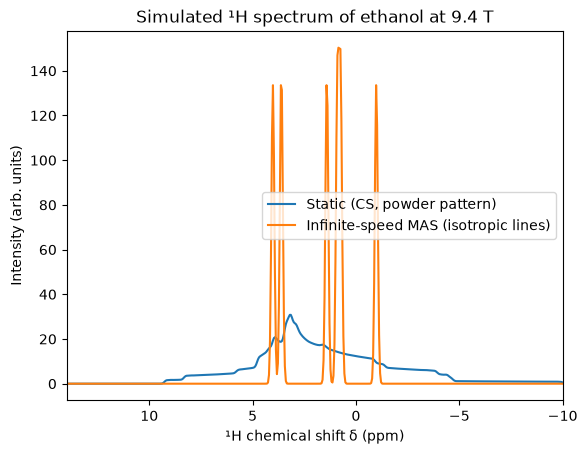

In [16]:
nCalc = NMRCalculator(ethanol, larmor_frequency=400, larmor_units='MHz')
print(f"Field: {nCalc.B:.2f} T")
nCalc.set_reference(REFERENCES['H'], '1H')
nCalc.set_powder(N=16)

h_window = dict(min_freq=-10, max_freq=14, bins=501)  # shift window, ppm
static_H, delta_H = nCalc.spectrum_1d('1H', effects=NMRFlags.STATIC, freq_broad=0.1, **h_window)
mas_H, _ = nCalc.spectrum_1d('1H', effects=NMRFlags.MAS, freq_broad=0.1, **h_window)

fig, ax = plt.subplots()
ax.plot(delta_H, static_H, label='Static (CS, powder pattern)')
ax.plot(delta_H, mas_H, label='Infinite-speed MAS (isotropic lines)')
ax.set_xlim(max(delta_H), min(delta_H))  # shift axis: high ppm on the left
ax.set_xlabel('¹H chemical shift δ (ppm)')
ax.set_ylabel('Intensity (arb. units)')
ax.set_title('Simulated ¹H spectrum of ethanol at 9.4 T')
ax.legend()
plt.show()

The static spectrum is a broad powder pattern, because each proton's shielding anisotropy is several ppm wide. Under infinite-speed MAS only the isotropic values survive, and the six protons collapse into three groups: the CH₂ protons near 4 ppm, the CH₃ protons near 1 ppm, and the hydroxyl proton near −1 ppm. The three CH₃ protons are not resolved from one another, and nothing in this calculation splits them, because couplings are left out. The two curves share one shift scale, so the static envelope and the MAS positions can be compared directly.

For ¹⁷O we switch isotope with `set_element_isotope('O', 17)`. Passing `freq_units='MHz'` sets both the window and the broadening in MHz relative to the ¹⁷O Larmor frequency ($\pm 8\text{ MHz}$, with 0.1 MHz broadening), wide enough to contain the full first-order satellite pattern (about $\pm 3.5\text{ MHz}$ for $C_Q \approx 11.2\text{ MHz}$).

We also pass `use_reference=True` so the axis is a frequency offset with higher frequency positive—otherwise, with no ¹⁷O reference set, Soprano stays on the shielding scale where positive values correspond to *lower* frequency. The default 0 ppm reference has no effect here because `Q_1_ORIENT` and `Q_STATIC` include only quadrupolar terms, not chemical shielding. Note that although $\gamma(^{17}\text{O}) < 0$ gives a negative Larmor frequency ($\approx -54.25\text{ MHz}$), Soprano scales MHz offsets by $|\nu_0|$, so higher frequency is always positive regardless of the sign of $\gamma$.

17O Larmor frequency: -54.25 MHz


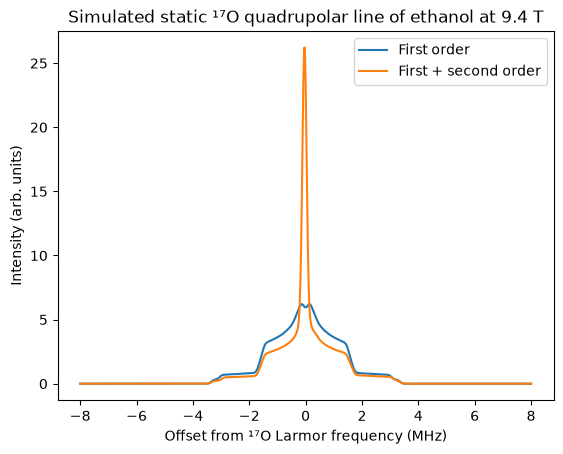

In [17]:
nCalc.set_element_isotope('O', 17)

o_window = dict(min_freq=-8, max_freq=8, bins=601, freq_units='MHz', use_reference=True)
first_O, offset_MHz = nCalc.spectrum_1d('17O', effects=NMRFlags.Q_1_ORIENT, freq_broad=0.1, **o_window)
second_O, _ = nCalc.spectrum_1d('17O', effects=NMRFlags.Q_STATIC, freq_broad=0.1, **o_window)

print(f"17O Larmor frequency: {nCalc.get_larmor_frequency('17O'):.2f} MHz")

fig, ax = plt.subplots()
ax.plot(offset_MHz, first_O, label='First order')
ax.plot(offset_MHz, second_O, label='First + second order')
ax.set_xlabel('Offset from ¹⁷O Larmor frequency (MHz)')
ax.set_ylabel('Intensity (arb. units)')
ax.set_title('Simulated static ¹⁷O quadrupolar line of ethanol at 9.4 T')
ax.legend()
plt.show()

The first-order curve (`Q_1_ORIENT`) shows the broad, symmetric satellite transitions spanning several MHz (set by $C_Q \approx 11.2\text{ MHz}$); first-order coupling leaves the central transition ($m = +\tfrac{1}{2} \leftrightarrow -\tfrac{1}{2}$) completely unbroadened (with zero orientational spread, it is omitted by the triangle-interpolated powder grid). Adding second-order terms (`Q_STATIC`) shifts the central transition to lower frequency (negative offset) and broadens it into a prominent, asymmetric powder peak a fraction of a MHz wide near the centre, while barely moving the outer satellite edges. Because second-order quadrupolar broadening scales as $C_Q^2 / |\nu_0|$, this central-transition pattern becomes wider at lower magnetic fields and narrower at higher fields (such as 14.1 T or 20 T).

**Limitations.** These spectra are guides for the eye and not spin simulations. They use the infinite-speed MAS limit only, so there are no spinning sidebands at finite speed. They omit dipolar and J couplings, so there are no multiplets. The powder average uses a finite grid and an artificial Gaussian broadening, not a physical linewidth. Quadrupolar effects are included only to second order. For finite-speed MAS, sidebands, couplings, or any pulse sequence, use SIMPSON or MRSimulator, which are covered in [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb).

## 8 - Advanced: reliability and caveats

*Skippable on a first read.*

The example files in this tutorial are small demonstration runs rather than production-converged calculations, and the accuracy of real GIPAW results depends on several choices that `.magres` files do not enforce automatically. Always check convergence with respect to the plane-wave cut-off and the $k$-point grid for each new system: shieldings and EFGs can converge more slowly than total energies, so a drift of even a few ppm in $\sigma$ when raising the cut-off is a warning sign.

Geometry matters at least as much. X–H bond lengths from X-ray diffraction are systematically too short (typically by ~0.1 Å), which noticeably shifts ¹H shieldings and O–H / C–H EFGs. Relaxing at least the hydrogen positions with the same functional used for the NMR calculation is standard practice. The exchange-correlation functional also shifts the absolute shielding scale, which is why references (Section 3.2) and linear calibrations (Section 3.3) belong to a specific computational protocol. Published GIPAW benchmarks on molecular crystals typically achieve RMS errors of a few tenths of a ppm for ¹H and ~2 ppm for ¹³C after referencing, though actual errors vary with the chemical system and method.

Finally, a single static 0 K structure omits thermal motion. Librations, methyl rotation, proton jumps, disorder, and thermal expansion all average the NMR tensors and shift the observed lines. When comparing with room-temperature spectra, you may need to average over molecular-dynamics snapshots or conformers—especially for EFGs, which are sensitive to small atomic displacements.

## 9 - Summary and next steps

In this tutorial you extracted reportable NMR parameters from a `.magres` file:

- Loaded `.magres` tensors into ASE `Atoms` objects and selected sites by label, index, and `AtomSelection`.
- Converted isotropic shieldings ($\sigma_{\text{iso}}$) to chemical shifts ($\delta$) using both the full single-reference formula and a linear calibration on L-alanine.
- Extracted shielding anisotropy and asymmetry (Haeberlen and Herzfeld–Berger), quadrupolar parameters ($V_{zz}$, $C_Q$, $\eta_Q$) for ²H and ¹⁷O, and pairwise dipolar and J couplings.
- Assembled a per-site summary table and exported it to CSV.
- Generated simple 1D static and infinite-speed MAS powder spectra with `NMRCalculator`, noting where a full spin simulator is needed.

**Next steps:**

- [Tutorial 5b](./05b-nmr-2d-spectra.ipynb) builds on the same referencing and `NMRCalculator` setup to create predicted 2D correlation maps (HETCOR and ¹H–¹H DQ/SQ).
- [Tutorial 5c](./05c-nmr-tensors-spin-systems.ipynb) covers tensor orientations (Euler angles) and exporting spin systems to SIMPSON and MRSimulator for finite-speed MAS and multi-spin simulations.
- The [Chemical shift referencing](../chemical-shift-referencing) guide gives the referencing equations, Soprano's warnings, and CLI equivalents.
- As a next exercise, try fitting a ¹H linear calibration across a small set of crystals with known experimental shifts to see how the intercept and slope behave.